<a href="https://colab.research.google.com/github/LanovenkoOleh/ML/blob/main/%D0%9B%D0%91_13_%D0%9C%D0%9D_%D0%9B%D0%B0%D0%BD%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Класифікація гральних карт за допомогою CNN та VGG16
Лановенко Олег Артемович, ФІТ 3-10

**Мета:** реалізувати класифікацію зображень гральних карт, підібрати параметри моделей та порівняти результати.

[Набір даних Kaggle](https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification).

## Task 1. Імпорт бібліотек

In [7]:
!pip -q install kagglehub

In [8]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score
from PIL import Image

np.random.seed(42)
tf.random.set_seed(42)

## Task 2. Завантаження набору даних

In [9]:
path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
print(path)
print(os.listdir(path))

train_path = os.path.join(path, 'train')
valid_path = os.path.join(path, 'valid')
test_path = os.path.join(path, 'test')
classes = sorted(os.listdir(train_path))
print('Кількість класів:', len(classes))
print(classes)

Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
/kaggle/input/cards-image-datasetclassification
['53cards-53-(200 X 200)-100.00.h5', 'cards.csv', 'valid', 'test', '14card types-14-(200 X 200)-94.61.h5', 'train']
Кількість класів: 53
['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades', 'four of clubs', 'four of diamonds', 'four of hearts', 'four of spades', 'jack of clubs', 'jack of diamonds', 'jack of hearts', 'jack of spades', 'joker', 'king of clubs', 'king of diamonds', 'king of hearts', 'king of spades', 'nine of clubs', 'nine of diamonds', 'nine of hearts', 'nine of spades', 'queen of clubs', 'queen of diamonds', 'queen of hearts', 'queen of spades', 'seven of clubs', 'seven of diamonds', 'seven of hearts', 'seven of spades', 'six of clubs', 'six of diamonds', 'six of hearts', 

## Task 3. Аналіз даних

,Клас,Train,Valid,Test
0,ace of clubs,120,5,5
1,ace of diamonds,129,5,5
2,ace of hearts,171,5,5
3,ace of spades,181,5,5
4,eight of clubs,138,5,5
5,eight of diamonds,159,5,5
6,eight of hearts,152,5,5
7,eight of spades,135,5,5
8,five of clubs,150,5,5
9,five of diamonds,138,5,5


Train    7624
Valid     265
Test      265
dtype: int64


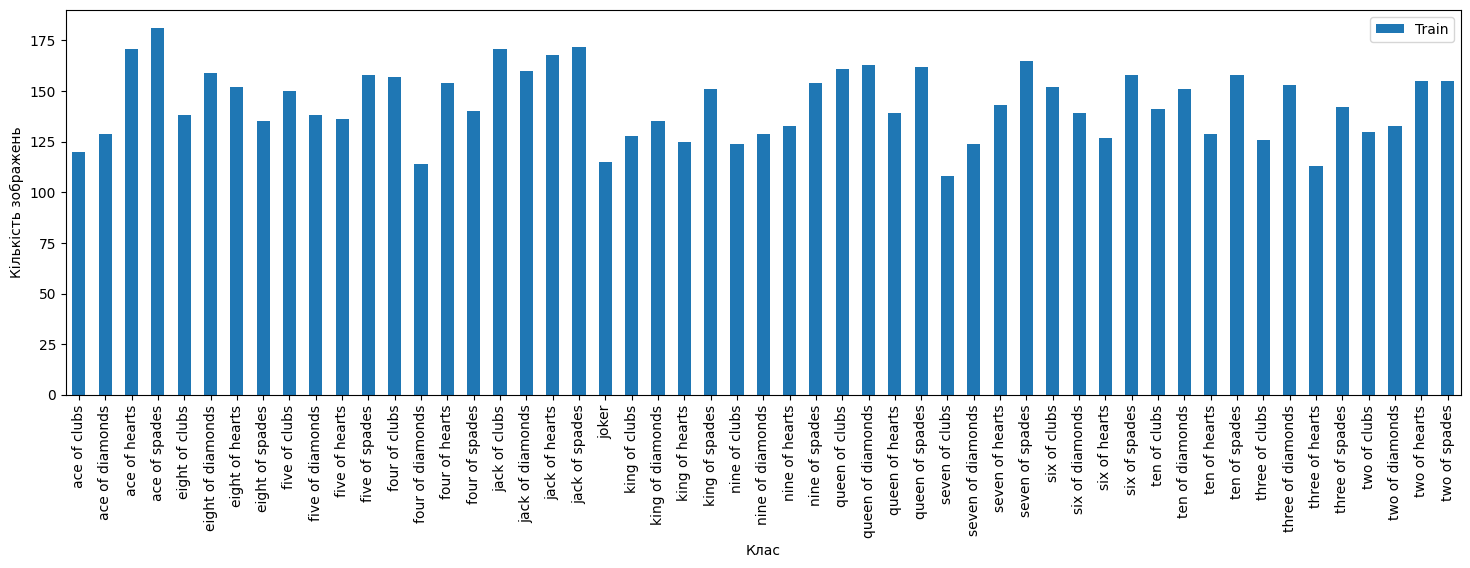

In [10]:
data = pd.DataFrame({'Клас': classes})
for name, folder in [('Train', train_path), ('Valid', valid_path), ('Test', test_path)]:
    data[name] = [len(os.listdir(os.path.join(folder, label))) for label in classes]

display(data)
print(data[['Train', 'Valid', 'Test']].sum())
data.plot(x='Клас', y='Train', kind='bar', figsize=(18, 5))
plt.ylabel('Кількість зображень')
plt.show()

## Task 4. Виведення зображень

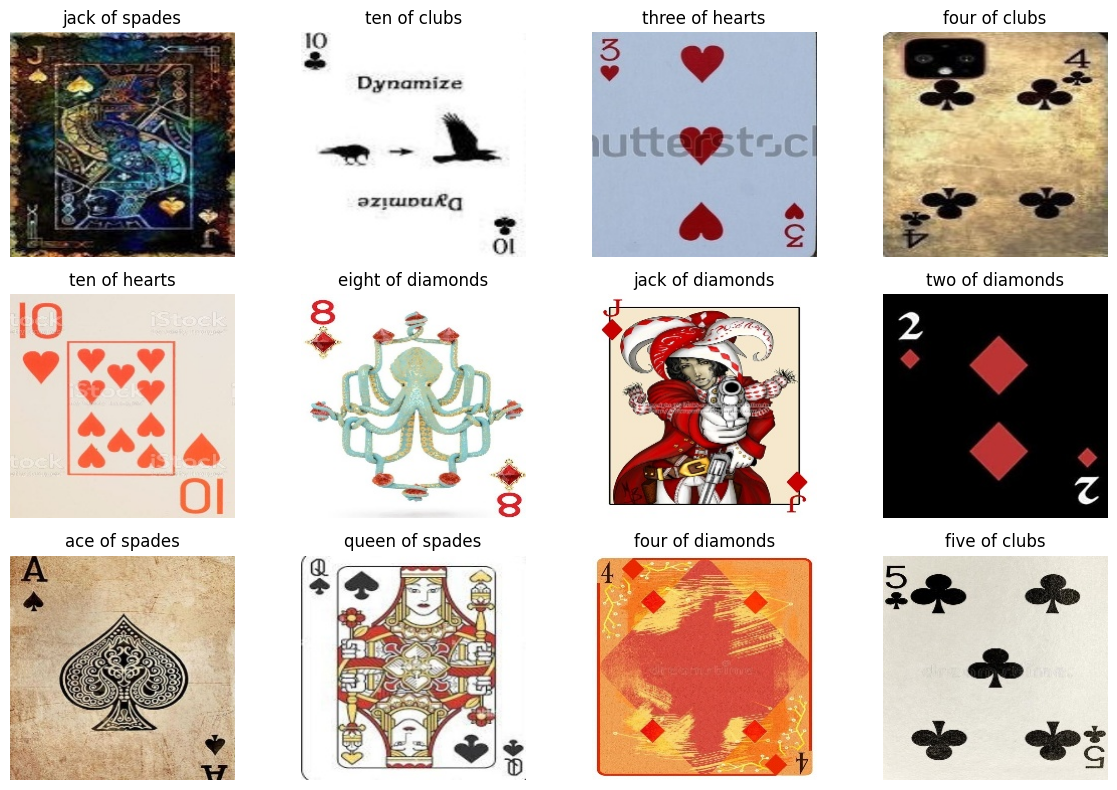

In [11]:
plt.figure(figsize=(12, 8))
for i, label in enumerate(np.random.choice(classes, 12, replace=False)):
    folder = os.path.join(train_path, label)
    img = Image.open(os.path.join(folder, np.random.choice(os.listdir(folder))))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(label)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Task 5. Підготовка даних
Зображення зменшуємо до 128×128 для швидшого навчання. Використовуємо готовий поділ на навчальну, валідаційну та тестову вибірки. Нормалізація CNN та попередня обробка VGG16 виконуються в самих моделях.

In [12]:
size = (128, 128)
batch_size = 32

train = tf.keras.utils.image_dataset_from_directory(train_path, class_names=classes, image_size=size, batch_size=batch_size, seed=42)
valid = tf.keras.utils.image_dataset_from_directory(valid_path, class_names=classes, image_size=size, batch_size=batch_size, shuffle=False)
test = tf.keras.utils.image_dataset_from_directory(test_path, class_names=classes, image_size=size, batch_size=batch_size, shuffle=False)

train = train.prefetch(tf.data.AUTOTUNE)
valid = valid.prefetch(tf.data.AUTOTUNE)
test = test.prefetch(tf.data.AUTOTUNE)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.


## Task 6. Побудова згорткової нейронної мережі

In [13]:
def create_cnn(filters, dropout, lr):
    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),
        layers.Rescaling(1./255),
        layers.Conv2D(filters, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Conv2D(filters*2, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Conv2D(filters*4, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(len(classes), activation='softmax')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

create_cnn(32, 0.3, 0.001).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 53)             │         6,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,294,517 (16.38 MB)

 Trainable params: 4,294,517 (16.38 MB)

 Non-trainable params: 0 (0.00 B)

## Task 7. Підбір параметрів CNN та рання зупинка
Порівнюємо три комбінації параметрів за точністю на валідаційній вибірці. EarlyStopping відновлює ваги найкращої епохи за val_accuracy.

In [15]:
def early_stop():
    return EarlyStopping(monitor='val_accuracy', mode='max', patience=1, restore_best_weights=True)

cnn_params = [(32, 0.3, 0.001), (64, 0.3, 0.001), (32, 0.5, 0.0005)]
cnn_results = []
cnn_score = -1

for filters, dropout, lr in cnn_params:
    model = create_cnn(filters, dropout, lr)

    history = model.fit(
        train,
        validation_data=valid,
        epochs=3,
        steps_per_epoch=20,
        callbacks=[early_stop()]
    )

    score = model.evaluate(valid, verbose=0)[1]
    cnn_results.append([filters, dropout, lr, score])

    if score > cnn_score:
        cnn_score = score
        best_cnn = model
        cnn_history = history

cnn_table = pd.DataFrame(cnn_results, columns=['Filters', 'Dropout', 'Learning rate', 'Val accuracy'])
display(cnn_table.sort_values('Val accuracy', ascending=False))

Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.0266 - loss: 4.0805 - val_accuracy: 0.0189 - val_loss: 3.9786
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.0250 - loss: 3.9645 - val_accuracy: 0.0679 - val_loss: 3.9381
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.0688 - loss: 3.8737 - val_accuracy: 0.1547 - val_loss: 3.7326
Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 84s 4s/step - accuracy: 0.0141 - loss: 4.0785 - val_accuracy: 0.0189 - val_loss: 3.9796
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.0328 - loss: 3.9605 - val_accuracy: 0.0189 - val_loss: 3.9669
Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.0219 - loss: 3.9981 - val_accuracy: 0.0377 - val_loss: 3.9614
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.0312 - loss: 3.9448 - val_accuracy: 0.0604 - val_loss: 3.8931
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.0562 - loss: 3.9075 - val_accuracy: 0.1245 - val_loss: 3.7626


,Filters,Dropout,Learning rate,Val accuracy
0,32,0.3,0.0010,0.154717
2,32,0.5,0.0005,0.124528
1,64,0.3,0.0010,0.018868


## Task 8. Побудова моделі VGG16
Використовуємо ваги ImageNet, спочатку заморожуємо згорткову основу та навчаємо новий класифікатор. Попередня обробка відповідає вимогам VGG16.

In [16]:
def create_vgg(dropout, lr):
    base = VGG16(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
    base.trainable = False
    inputs = layers.Input(shape=(128, 128, 3))
    x = layers.Lambda(preprocess_input)(inputs)
    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(len(classes), activation='softmax')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model, base

vgg, base = create_vgg(0.3, 0.001)
vgg.summary()
del vgg, base

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 53)             │         6,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,787,189 (56.41 MB)

 Trainable params: 72,501 (283.21 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Task 9. Підбір параметрів VGG16

In [18]:
vgg_params = [(0.3, 0.001), (0.5, 0.0005)]
vgg_results = []
vgg_score = -1

for dropout, lr in vgg_params:
    model, base = create_vgg(dropout, lr)

    history = model.fit(
        train,
        validation_data=valid,
        epochs=3,
        steps_per_epoch=5,
        callbacks=[early_stop()]
    )

    score = max(history.history['val_accuracy'])
    vgg_results.append([dropout, lr, score])

    if score > vgg_score:
        vgg_score = score
        best_vgg = model
        best_base = base
        vgg_history = history

vgg_table = pd.DataFrame(vgg_results, columns=['Dropout', 'Learning rate', 'Val accuracy'])
display(vgg_table.sort_values('Val accuracy', ascending=False))

Epoch 1/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 98s 22s/step - accuracy: 0.0125 - loss: 13.0881 - val_accuracy: 0.0415 - val_loss: 9.3808
Epoch 2/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 116s 28s/step - accuracy: 0.0437 - loss: 9.0144 - val_accuracy: 0.0642 - val_loss: 7.9071
Epoch 3/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 117s 28s/step - accuracy: 0.0125 - loss: 8.1709 - val_accuracy: 0.0679 - val_loss: 6.8273
Epoch 1/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 120s 28s/step - accuracy: 0.0250 - loss: 18.2387 - val_accuracy: 0.0340 - val_loss: 11.7214
Epoch 2/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 93s 22s/step - accuracy: 0.0188 - loss: 16.4195 - val_accuracy: 0.0491 - val_loss: 9.9042
Epoch 3/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 118s 28s/step - accuracy: 0.0063 - loss: 13.6886 - val_accuracy: 0.0491 - val_loss: 8.6557


,Dropout,Learning rate,Val accuracy
0,0.3,0.0010,0.067925
1,0.5,0.0005,0.049057


## Task 10. Донавчання VGG16 (Fine-tuning)
Розморожуємо останній згортковий блок та продовжуємо навчання з меншою швидкістю. Якщо точність погіршиться, залишаємо ваги попереднього етапу.

In [21]:
old_weights = best_vgg.get_weights()
best_base.trainable = True

for layer in best_base.layers:
    layer.trainable = layer.name.startswith('block5')

best_vgg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])

fine_history = best_vgg.fit(
    train,
    validation_data=valid,
    epochs=3,
    steps_per_epoch=5,
    callbacks=[early_stop()]
)

fine_score = max(fine_history.history['val_accuracy'])

print('До донавчання:', vgg_score)
print('Після донавчання:', fine_score)

if fine_score < vgg_score:
    best_vgg.set_weights(old_weights)
else:
    vgg_score = fine_score

Epoch 1/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 130s 29s/step - accuracy: 0.0437 - loss: 4.9988 - val_accuracy: 0.0415 - val_loss: 5.2411
Epoch 2/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 123s 29s/step - accuracy: 0.0938 - loss: 4.5107 - val_accuracy: 0.0491 - val_loss: 4.9513
Epoch 3/3
5/5 ━━━━━━━━━━━━━━━━━━━━ 100s 23s/step - accuracy: 0.0437 - loss: 4.8046 - val_accuracy: 0.0491 - val_loss: 4.7433
До донавчання: 0.06792452931404114
Після донавчання: 0.049056604504585266


## Task 11. Побудова кривих навчання

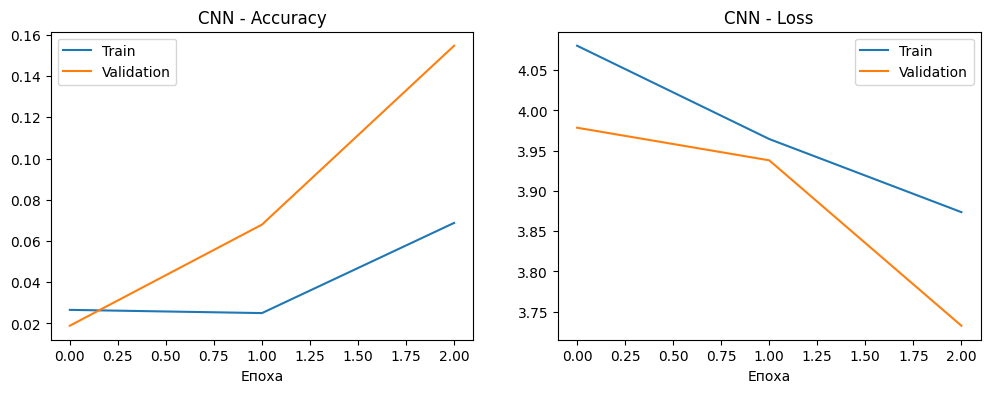

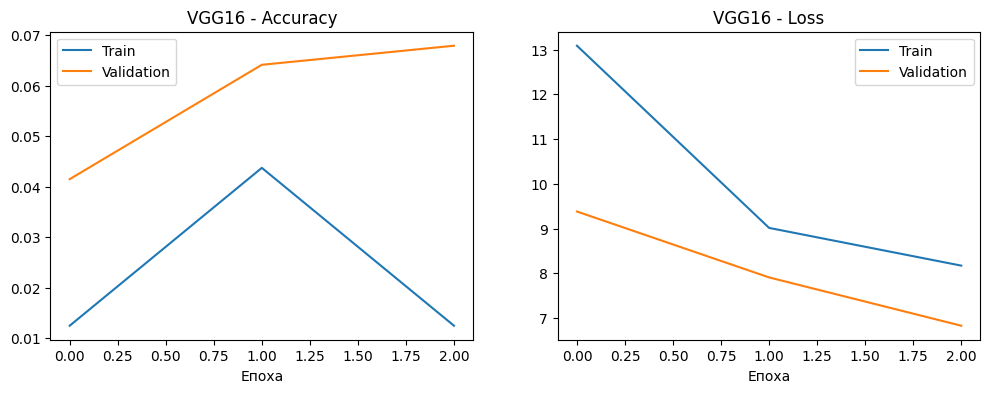

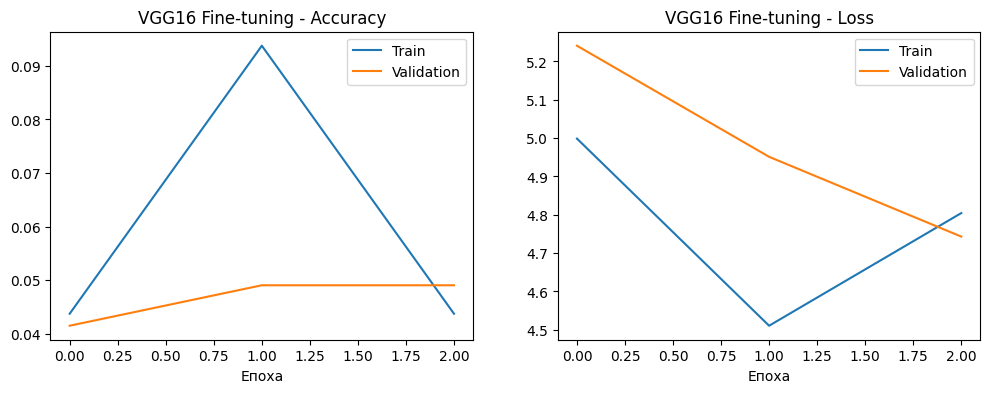

In [22]:
def plot_history(history, name):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title(name + ' - Accuracy')
    plt.xlabel('Епоха')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title(name + ' - Loss')
    plt.xlabel('Епоха')
    plt.legend()
    plt.show()

plot_history(cnn_history, 'CNN')
plot_history(vgg_history, 'VGG16')
plot_history(fine_history, 'VGG16 Fine-tuning')

## Task 12. Оцінювання та порівняння моделей
Найкращу модель обираємо за валідаційною точністю. Тестова вибірка використовується лише для фінальної оцінки.

,Модель,Val accuracy,Test accuracy,Test loss,Macro F1
0,CNN,0.154717,0.139623,3.704142,0.075440
1,VGG16,0.067925,0.030189,5.376283,0.021586


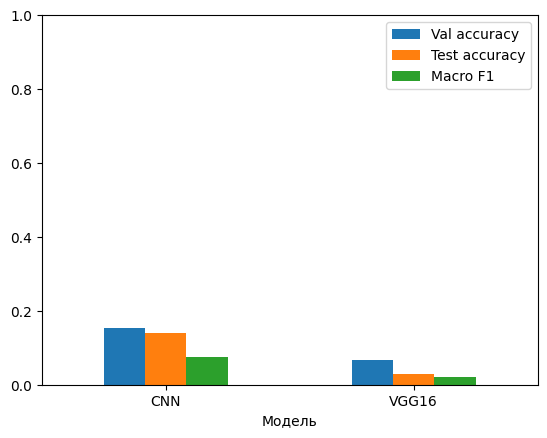

Найкраща модель: CNN


In [23]:
y_true = np.concatenate([labels.numpy() for images, labels in test])
results = []
for name, model, score in [('CNN', best_cnn, cnn_score), ('VGG16', best_vgg, vgg_score)]:
    loss, acc = model.evaluate(test, verbose=0)
    y_pred = np.argmax(model.predict(test, verbose=0), axis=1)
    results.append([name, score, acc, loss, f1_score(y_true, y_pred, average='macro')])

results = pd.DataFrame(results, columns=['Модель', 'Val accuracy', 'Test accuracy', 'Test loss', 'Macro F1'])
display(results)
results.plot(x='Модель', y=['Val accuracy', 'Test accuracy', 'Macro F1'], kind='bar', ylim=(0, 1), rot=0)
plt.show()

best_name = results.loc[results['Val accuracy'].idxmax(), 'Модель']
best_model = best_cnn if best_name == 'CNN' else best_vgg
print('Найкраща модель:', best_name)

## Task 13. Візуалізація класифікації

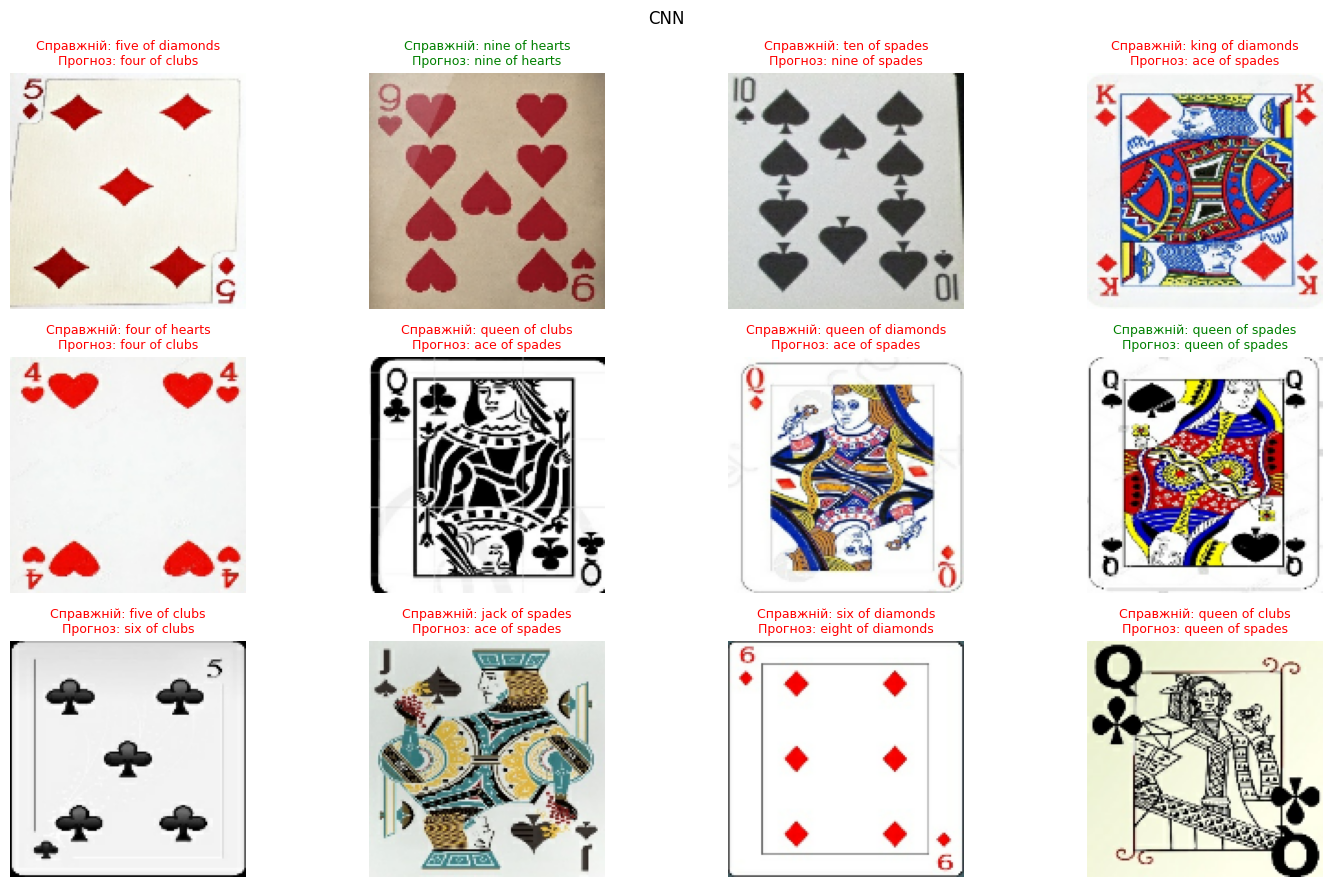

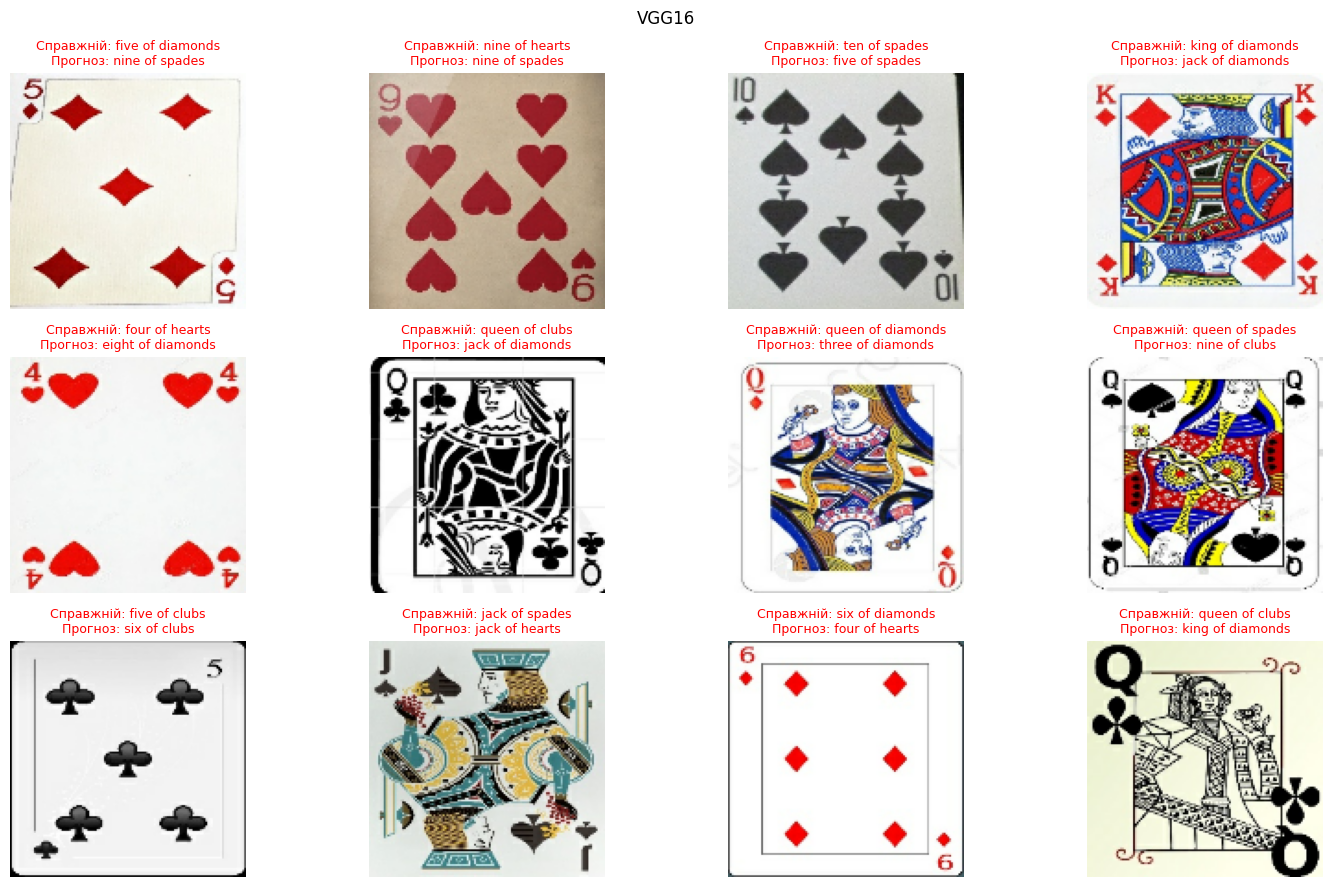

In [24]:
images, labels = next(iter(test.unbatch().shuffle(len(y_true), seed=42).batch(12)))
for name, model in [('CNN', best_cnn), ('VGG16', best_vgg)]:
    predictions = np.argmax(model.predict(images, verbose=0), axis=1)
    plt.figure(figsize=(15, 9))
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        true = classes[int(labels[i])]
        pred = classes[predictions[i]]
        plt.title('Справжній: ' + true + '\nПрогноз: ' + pred, color='green' if true == pred else 'red', fontsize=9)
        plt.axis('off')
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

## Висновок
У ході виконання лабораторної роботи реалізовано класифікацію зображень гральних карт за допомогою власної згорткової нейронної мережі та попередньо навченої моделі VGG16. Проведено аналіз даних, зміну розміру зображень, попередню обробку, підбір параметрів та ранню зупинку навчання. Для VGG16 застосовано перенесення навчання та донавчання останнього згорткового блоку. Побудовано криві навчання та візуалізовано результати класифікації. Числові результати та остаточний висновок формуються після виконання блоків.

In [25]:
for _, row in results.iterrows():
    print(f"{row['Модель']}: accuracy = {row['Test accuracy']:.4f}, F1 = {row['Macro F1']:.4f}")
print('За валідаційною точністю найкращою є модель', best_name)
if fine_score > vgg_results[np.argmax(vgg_table['Val accuracy'])][2]:
    print('Донавчання VGG16 покращило валідаційну точність.')
elif fine_score < max(vgg_table['Val accuracy']):
    print('Донавчання не покращило результат, тому відновлено попередні ваги.')
else:
    print('Донавчання не змінило валідаційну точність.')

CNN: accuracy = 0.1396, F1 = 0.0754
VGG16: accuracy = 0.0302, F1 = 0.0216
За валідаційною точністю найкращою є модель CNN
Донавчання не покращило результат, тому відновлено попередні ваги.
